### Building a CNN using Pytorch on MNIST fashion data

Downloaded data, wrote class for simple CNN with 2 convolution layers and 2 fully connected layers that output 10 logits. Across 5 epochs in training, the model had 91.1% training accuracy and 89.5% test accuracy. The model generalizes well. 

Confirmed correct implementation of conv, pool, FC architecture before moving onto biological image data. 

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

Importing torch 

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


Downloading the fashion MNIST dataset to learn.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")

Train size: 60000, Test size: 10000


Let's see the images. 

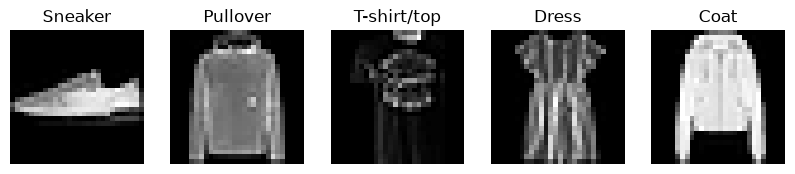

In [4]:
images, labels = next(iter(train_loader))
fig, axs = plt.subplots(1, 5, figsize=(10, 2))
for i in range(5):
    axs[i].imshow(images[i][0], cmap="gray")
    axs[i].set_title(train_dataset.classes[labels[i]])
    axs[i].axis("off")
plt.show()

Create a class called Simple CNN. It sets up 2 convolution layers and 2 fully connected layers.

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10): 
        super(SimpleCNN, self).__init__()
        # raw image goes into conv1 layer with 1 channel (greyscale), kernel is 3x3, and there are 16 diff kernels, padding is 1 all around image 
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)

        # conv1 takes in 16 feature maps (each kernel works with 3x3x16), there are 32 diff kernels of size 3x3x16 that multiply against each block and produce 1 scalar for each 
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        # a 2x2 square goes through and takes the higher value to reduce resolution per channel 
        # pooling happens after every layer 
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # fully connected layer 1 takes the 7x7x32 grid and flattens to a 1D array that maps to 128 nodes
        self.fc1 = nn.Linear(32 * 7 * 7, 128)

        # fc2 then connects to the final number of logits (10)
        self.fc2 = nn.Linear(128, num_classes)

    # forward pass through all layers gives an initial output, not learning yet 
    def forward(self, x):
        # sends x through convolutional layer 1, then relu, then pool
        x = self.pool(F.relu(self.conv1(x)))   # 28x28 -> 14x14

        # sends new x through conv2, same process 
        x = self.pool(F.relu(self.conv2(x)))   # 14x14 -> 7x7

        # the 7x7x32 block then gets flattened into a 1D array
        x = x.view(x.size(0), -1)              # flatten

        # send 1D x into fc1, then relu
        x = F.relu(self.fc1(x))

        # lastly, into fc2 to get 10 logits 
        x = self.fc2(x)
        return x

# instance of the class
model = SimpleCNN(num_classes=10).to(device)
print(model)

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


Training loop

In [6]:
# Loss function and optimizer
criterion = nn.CrossEntropyLoss() # loss calculator 
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5

# each epoch is all of the training dataset 
for epoch in range(num_epochs):
    model.train()  # tells the model it's in training mode 
    running_loss = 0.0
    correct = 0
    total = 0

    # 938 batches in 1 epoch 
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # 1. Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels) # calculates how wrong the prediction was 

        # 2. Backward pass
        optimizer.zero_grad() # clear old gradients before computing new ones. gradients track who contributes to loss and by how much. we want to clear because we're testing each batch separately 
        loss.backward() # backprops to see who was responsible for contributing to the loss 

        # 3. Optimizer step — this is where learning actually happens
        optimizer.step() # weights update 

        # Bookkeeping for reporting
        # keep track of total loss per batch 
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    # ratio of loss in the epoch 
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs} — Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_acc:.4f}")

Epoch 1/5 — Loss: 0.5370, Train Accuracy: 0.8033
Epoch 2/5 — Loss: 0.3416, Train Accuracy: 0.8760
Epoch 3/5 — Loss: 0.2933, Train Accuracy: 0.8928
Epoch 4/5 — Loss: 0.2632, Train Accuracy: 0.9037
Epoch 5/5 — Loss: 0.2382, Train Accuracy: 0.9116


How well does it generalize on test data?

In [7]:
model.eval()  # switches model to evaluation mode
correct = 0
total = 0

with torch.no_grad():  # disables gradient tracking — we're not training here
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

test_acc = correct / total
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.8952
